# La referencia del motor, el documento de disponibilidad y el contrato de la API: qué registra cada uno y cómo los usa un lector

**Pregunta:** ¿Cómo se mantiene el motor TypeScript del navegador dentro de una tolerancia declarada respecto del motor de Python, qué registran el documento de disponibilidad y el contrato de la API sobre el resto del producto, y cómo distingue un lector, a partir de ellos, qué es confiable?

- Nivel: 2, el método en la práctica. Contratos: engine-reference, readiness y api.
- Requisitos previos: `01-fourier-optics/02-reading-a-trap-array`, que lee los contratos de casos junto a los cuales están estos tres.
- Tiempo de lectura: unos 30 minutos. El notebook se ejecuta en cerca de 10 segundos.

## Objetivos

DinHot calcula los mismos hologramas en dos lugares: el motor de Python del pipeline y un motor TypeScript en el navegador. Un usuario confía en el segundo solo si algo lo ata al primero, y confía en un número de la pantalla solo si el producto dice de qué se construyó. La lección de este notebook es la aritmética de ese lazo: una regla de aceptación con dos tolerancias, el tamaño desde el cual empieza a rechazar un port y el argumento de redondeo de por qué un port debe quedarse en doble precisión; los contratos de disponibilidad y de la API se leen como la parte del producto que dice para qué se puede confiar en los números. Tres contratos llevan el lazo: la referencia del motor, que guarda las respuestas del motor de Python para que las pruebas de TypeScript las comparen, el documento de disponibilidad, que dice para cada contrato si está disponible, parcial, desactualizado o aún servido por un sustituto, y el contrato de la API, que dice qué responde el servicio cuando algo falta. Al terminar puedes:

- leer un documento de referencia del motor, decodificar sus arreglos y enunciar la regla con que se acepta un port;
- hallar, con un barrido, el tamaño de una diferencia desde el cual esa regla empieza a fallar, y decir por qué un port en precisión simple la incumpliría;
- leer el documento de disponibilidad fila por fila, decir qué significa cada estado y procedencia, y listar lo que no está disponible y por qué;
- leer el contrato de la API y decir qué recibe quien llama de cada ruta cuando falta su documento;
- escribir un documento de referencia para una función propia y elegir su tolerancia a partir de evidencia.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas (matplotlib 3.11.2 es la biblioteca de gráficos listada en https://pypi.org/pypi/matplotlib/json):

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import base64
import json
import sys
from collections import Counter
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.holo.core import forward
from pipeline.model.holo.core.geometry import Setup
from pipeline.stages import engine_reference as stage

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee tres documentos versionados, cada uno salida de una etapa o contrato mantenido a mano, y un archivo de texto:

- `tests/fixtures/engine/*.json`: la referencia del motor, un documento por función o método del motor de Python (46 archivos);
- `data/derived/readiness.json`: el documento de disponibilidad, una fila por contrato;
- `docs/contracts/api.openapi.json`: el contrato de la API, en forma OpenAPI;
- `docs/contracts/catalog.md`: el catálogo cuyas filas leen las reglas de disponibilidad.

Propietario: este repositorio; los cuatro los genera o mantiene el producto, sin conjuntos de datos de terceros. Clase de licencia: la licencia del propio repositorio. Los documentos de referencia usan semillas: sus entradas se guardan con sus salidas, de modo que un lector no necesita otro archivo para usarlos.

In [2]:
# la referencia del motor (46 documentos), el documento de disponibilidad y el contrato de la API
reference = {
    p.stem: json.loads(p.read_text(encoding="utf-8"))
    for p in sorted((ROOT / "tests/fixtures/engine").glob("*.json"))
}
readiness = json.loads((ROOT / "data/derived/readiness.json").read_text(encoding="utf-8"))
openapi = json.loads((ROOT / "docs/contracts/api.openapi.json").read_text(encoding="utf-8"))
product_version = (ROOT / "VERSION").read_text(encoding="utf-8").strip()
cases_total = sum(len(d["cases"]) for d in reference.values())
print(
    len(reference),
    "documentos de referencia,",
    cases_total,
    "casos | esquema",
    {d["schema"] for d in reference.values()},
)
print(
    len(readiness["contracts"]),
    "filas de disponibilidad | producto",
    readiness["product_version"],
    "| rutas de la API",
    len(openapi["paths"]),
)

46 documentos de referencia, 119 casos | esquema {'dinhot.engine-ref/v1'}
11 filas de disponibilidad | producto 0.02.002 | rutas de la API 8


## Método

### Paso 1: qué registra un documento de referencia

Un documento de referencia guarda una función o un método del motor de Python. Declara el nombre, el esquema `dinhot.engine-ref/v1`, la versión del motor que lo escribió, una tolerancia y una lista de casos. Cada caso tiene `inputs` y `outputs`, y las entradas tienen semilla y se guardan, de modo que la prueba de TypeScript lee ambas del archivo y no regenera nada. Un arreglo numérico se guarda como `{shape, complex, data}` cuando tiene a lo más 64 valores y como `{shape, complex, b64}` sobre eso, con los valores como float64 little-endian y los complejos intercalados como parte real e imaginaria; los enteros y escalares son JSON simple. La tolerancia es un par, una parte absoluta y una relativa, que se aplica a toda cantidad flotante del documento salvo que un caso lleve la suya. La celda lista lo que guardan los 46 documentos, cómo se codifican sus arreglos y cuántos exigen igualdad exacta.

In [3]:
# lo que guardan los 46 documentos: funciones, casos, codificaciones y tolerancias
def count_arrays(node):
    inline = int(isinstance(node, dict) and "shape" in node and "data" in node)
    packed = int(isinstance(node, dict) and "shape" in node and "b64" in node)
    kids = node.values() if isinstance(node, dict) else node if isinstance(node, list) else ()
    for kid in kids:
        a, b = count_arrays(kid)
        inline, packed = inline + a, packed + b
    return inline, packed


encodings = np.array([count_arrays(d["cases"]) for d in reference.values()]).sum(axis=0)
exact = [name for name, d in reference.items() if d["tolerance"] == {"abs": 0.0, "rel": 0.0}]
tight = min(d["tolerance"]["rel"] for d in reference.values() if d["tolerance"]["rel"] > 0)
loose = max(d["tolerance"]["rel"] for d in reference.values())
print(len(exact), "documentos exigen igualdad exacta (abs y rel cero):", exact)
print("arreglos guardados en línea:", int(encodings[0]), "| arreglos guardados como b64:", int(encodings[1]))
print(
    "versiones del motor que los escribieron:",
    sorted({d["engine_version"] for d in reference.values()}),
    "| product",
    product_version,
)
print(f"tolerancia relativa más estricta {tight:.0e} | más laxa {loose:.0e}")

2 documentos exigen igualdad exacta (abs y rel cero): ['device.quantize', 'zernike.noll_to_nm']
arreglos guardados en línea: 77 | arreglos guardados como b64: 152
versiones del motor que los escribieron: ['0.02.000', '0.02.002'] | product 0.02.002
tolerancia relativa más estricta 1e-14 | más laxa 1e-08


La figura pone cada documento en su tolerancia absoluta y relativa en ejes logarítmicos; los documentos con tolerancia exactamente cero no se dibujan.

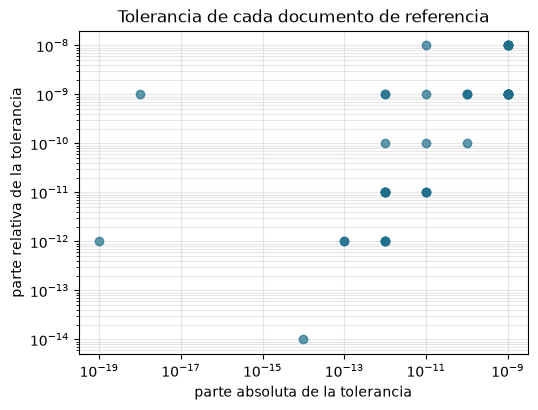

In [4]:
# la tolerancia de cada documento: la parte absoluta frente a la relativa
points = np.array(
    [(d["tolerance"]["abs"], d["tolerance"]["rel"]) for d in reference.values() if d["tolerance"]["rel"] > 0]
)
fig, ax = plt.subplots(figsize=(5.8, 4.2))
ax.loglog(points[:, 0].clip(1e-19), points[:, 1], "o", color="#1f6f8b", alpha=0.7)
ax.set_xlabel("parte absoluta de la tolerancia")
ax.set_ylabel("parte relativa de la tolerancia")
ax.set_title("Tolerancia de cada documento de referencia")
ax.grid(True, which="both", alpha=0.3)
plt.show()

Los 46 documentos guardan 119 casos y 77 arreglos en línea y 152 empaquetados en base64, y 2 de ellos piden igualdad exacta, el cuantizador y el mapa de índices de Noll, cuyas salidas son niveles y enteros. Las tolerancias van de una relativa de 1e-14 a 1e-08, y la figura muestra que no son un solo número: un documento de aritmética simple, como una envolvente de píxel, se mantiene en cerca de $10^{-12}$, mientras los documentos de métodos completos que iteran, cuyo redondeo se acumula en el lazo, se mantienen en cerca de $10^{-8}$. La razón de cada tolerancia está escrita en el informe que la produjo, no en el documento, por lo que un lector debe tratar la figura como un registro de lo que el port necesitó y no como una afirmación de lo que la matemática permite. Los puntos con parte absoluta cero se dibujan en el piso del eje. Las versiones de lo impreso son las del motor que escribió los archivos: dicen 0.02.000 mientras el producto es 0.02.002, y las reglas de disponibilidad no marcan este contrato como desactualizado por eso, ya que una referencia es una entrada de prueba y no una generación del motor del día.

### Paso 2: la regla de aceptación, y el motor de Python frente a su propia referencia

Un port se acepta en un documento cuando toda cantidad flotante de todo caso cumple, para el valor de referencia $r_i$ y el valor del port $a_i$,

$$\lvert a_i - r_i \rvert \le \tau_{\mathrm{abs}} + \tau_{\mathrm{rel}}\,\lvert r_i \rvert,$$

con $\tau_{\mathrm{abs}}$ y $\tau_{\mathrm{rel}}$ el par del documento, o del caso si lo sobrescribe, y cuando todo flujo entero es idéntico. La parte absoluta mantiene la regla con sentido donde la referencia es cercana a cero y la relativa donde es grande. Las pruebas de TypeScript aplican esta regla al motor del navegador; el notebook no puede correr el TypeScript, de modo que hace lo que puede hacer del lado de Python. Escribe la regla como una función que decodifica un documento y devuelve la mayor fracción de la tolerancia que usa algún valor, y, como su única comprobación de reproducción, regenera los 42 documentos que produce la etapa sin las corridas largas de la grilla en vivo, con el propio `all_documents` de la etapa, para ver si los archivos versionados siguen describiendo el motor que está en el repositorio.

In [5]:
# la regla de la referencia como dos funciones: decodificar un arreglo guardado, y la fracción de la tolerancia
# que usa un valor
def decode(node):
    if isinstance(node, dict) and "shape" in node:
        raw = base64.b64decode(node["b64"]) if "b64" in node else None
        values = np.frombuffer(raw, dtype="<f8") if raw is not None else np.asarray(node["data"], dtype=float)
        if node["complex"]:
            values = values[0::2] + 1j * values[1::2]
        return values.reshape(node["shape"])
    return np.asarray(node)


def margin(port, ref, tol):
    """Largest share de los tolerance used by any value: at most 1 means the rule holds."""
    a, r = decode(port), decode(ref)
    return (
        float(np.max(np.abs(a - r) / (tol["abs"] + tol["rel"] * np.abs(r))))
        if tol["abs"] + tol["rel"] > 0
        else float(np.any(a != r))
    )

La celda siguiente regenera los 42 documentos con el motor del repositorio y los compara con los versionados.

In [6]:
# el motor de Python regenerado frente a los documentos versionados (la única comprobación de reproducción)
fresh = {}
for key, produced in stage.all_documents(live=False).items():
    fresh[key] = json.loads(stage.dump(produced))
used = {}
for name, doc in fresh.items():
    shares = []
    for new_case, old_case in zip(doc["cases"], reference[name]["cases"]):
        for key, old in old_case["outputs"].items():
            if isinstance(old, dict) and "shape" in old:
                shares.append(margin(new_case["outputs"][key], old, reference[name]["tolerance"]))
    used[name] = max(shares, default=0.0)
same = sum(1 for name, doc in fresh.items() if doc["cases"] == reference[name]["cases"])
print(same, "de los", len(fresh), "documentos se regeneran con casos idénticos:", same == len(fresh))
print(f"mayor margen usado (1 es el borde de la tolerancia): {max(used.values()):.3g}")

42 de los 42 documentos se regeneran con casos idénticos: True
mayor margen usado (1 es el borde de la tolerancia): 0


42 de los 42 documentos se regeneran con casos idénticos a los versionados, y la mayor fracción de la tolerancia que usa algún valor es 0. De modo que la referencia versionada describe exactamente el motor de Python del repositorio, que es lo que afirma la prueba de contrato de la etapa al regenerar y comparar, y el port de TypeScript es lo único entre los dos que tiene espacio para diferir. Es una afirmación sobre el repositorio de hoy y una corrida de la etapa; no dice nada del TypeScript, y una referencia que se hubiera alejado en silencio del motor convertiría un port que falla en uno que pasa, razón por la que la regeneración es parte de las pruebas del producto y no una opción.

### Sensibilidad de la regla de aceptación al tamaño de una diferencia

La regla tiene un tamaño incorporado, la tolerancia, y la pregunta útil es qué significa ese tamaño en términos de ports que existen. La celda toma las salidas flotantes de tres documentos, la diafonía del modelo del dispositivo, el campo focal del modelo directo y el lazo ponderado M06, agrega a cada valor una diferencia relativa $\delta$ de $10^{-16}$ a $10^{-4}$ y mide la fracción de valores que quedan dentro de la tolerancia. Agrega un caso que no es construido, los mismos valores convertidos a precisión simple, la aritmética de un port que no usó dobles; para un número float32 el error de redondeo está acotado por la unidad de redondeo

$$u = 2^{-24} \approx 6 \times 10^{-8}$$

en términos relativos (Higham, 2002, capítulo 2; IEEE 754-2019; Goldberg, 1991, sobre el redondeo de la aritmética de punto flotante), de modo que un port que guarda valores intermedios en precisión simple difiere de la referencia en cerca de $u\,\lvert r_i \rvert$ en cada valor, lo que está sobre toda tolerancia de la figura del paso 1.

In [7]:
# una diferencia de tamaño relativo delta agregada a cada valor de tres documentos, y los mismos valores en
# precisión simple
deltas = 10.0 ** np.arange(-16, -3.9, 0.5)
sweep = {}
for name in ("device.crosstalk", "forward.fft_focal_field", "methods.M06"):
    tol = reference[name]["tolerance"]
    refs = np.concatenate(
        [
            np.ravel(decode(v)).view(float) if np.iscomplexobj(decode(v)) else np.ravel(decode(v))
            for c in reference[name]["cases"]
            for v in c["outputs"].values()
            if isinstance(v, dict) and "shape" in v
        ]
    )
    band = tol["abs"] + tol["rel"] * np.abs(refs)
    passing = [float(np.mean(np.abs(d * refs) <= band)) for d in deltas]
    single = float(np.mean(np.abs(refs.astype(np.float32).astype(np.float64) - refs) <= band))
    sweep[name] = (passing, single, tol["rel"])
    print(f"{name:26s} relative tolerance {tol['rel']:.0e} | precisión simple: fracción aceptada {single:.3f}")

device.crosstalk           relative tolerance 1e-11 | precisión simple: fracción aceptada 0.001
forward.fft_focal_field    relative tolerance 1e-11 | precisión simple: fracción aceptada 0.001
methods.M06                relative tolerance 1e-09 | precisión simple: fracción aceptada 0.066


Las curvas grafican la fracción de valores aceptados frente a la diferencia relativa; los marcadores de la derecha son la conversión a precisión simple de cada documento.

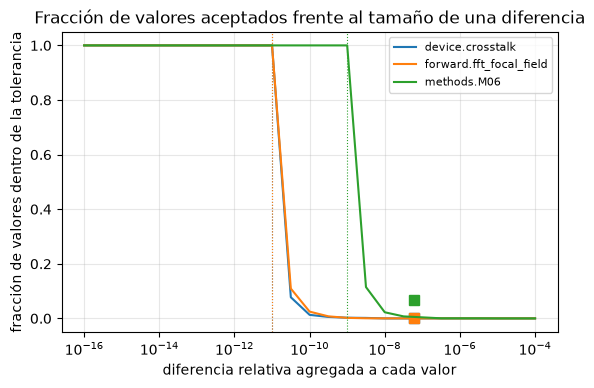

In [8]:
# the share of values accepted against the relative difference, and the single-precision cast of each document
fig, ax = plt.subplots(figsize=(6.4, 3.9))
for name, (passing, single, rel) in sweep.items():
    line = ax.semilogx(deltas, passing, "-", label=name)[0]
    ax.plot([6e-8], [single], "s", color=line.get_color(), markersize=7)
    ax.axvline(rel, color=line.get_color(), linestyle=":", linewidth=0.8)
ax.set_xlabel("diferencia relativa agregada a cada valor")
ax.set_ylabel("fracción de valores dentro de la tolerancia")
ax.set_title("Fracción de valores aceptados frente al tamaño de una diferencia")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)
plt.show()

Cada curva cae de 1 a 0 en cerca de una década, y la caída ocurre en la tolerancia relativa de su documento, marcada por la línea punteada del mismo color: 1e-11 para la diafonía, 1e-11 para el campo focal y 1e-09 para M06. Bajo esa línea una diferencia es invisible para la regla y sobre ella se rechaza todo valor, de modo que la tolerancia es la resolución de la verificación y no un margen de seguridad encima de ella. Los cuadrados son la conversión a precisión simple, dibujados en $u$: están en 0,001, 0,001 y 0,066 de los valores aceptados, de modo que un port en precisión simple fallaría los tres, que es el argumento para mantener el motor del navegador en dobles. La figura usa una diferencia de un solo tamaño para todos los valores, un port idealizado; un port real difiere en una cantidad que depende del valor, lo que la conversión a precisión simple imita mejor, y el árbitro real es la propia prueba de TypeScript.

El barrido perturbó las salidas. Un port también difiere en lo que recibe, de modo que la celda siguiente perturba las fases de entrada del propio motor en una cantidad relativa $\varepsilon$ y mide cuánto de eso llega al campo focal, relativo a su pico. Si la transformada no amplificara las diferencias, la salida cambiaría en cerca de $\varepsilon$ por el tamaño de las fases, y una tolerancia de $10^{-11}$ exigiría entonces que las entradas de un port coincidan hasta cerca de $10^{-11}$, que es la razón por la que la referencia guarda las entradas junto con las salidas.

fases de entrada desviadas en 1e-14: mayor diferencia de salida relativa al pico 7.11e-14
fases de entrada desviadas en 1e-12: mayor diferencia de salida relativa al pico 7.11e-12
fases de entrada desviadas en 1e-10: mayor diferencia de salida relativa al pico 7.11e-10
fases de entrada desviadas en 1e-08: mayor diferencia de salida relativa al pico 7.11e-08
fases de entrada desviadas en 1e-06: mayor diferencia de salida relativa al pico 7.11e-06
diferencia de salida sobre diferencia de entrada en 1e-06: 7.1


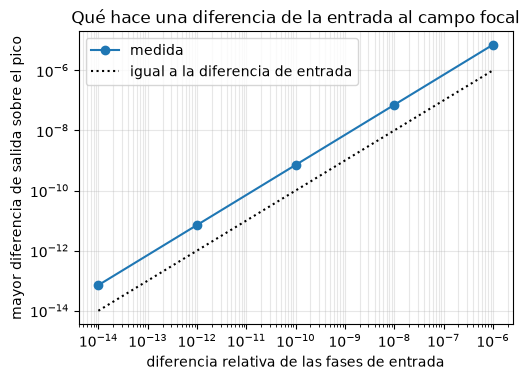

In [9]:
# el motor con fases desviadas en una cantidad relativa eps: cuánto de la diferencia de entrada llega al campo focal
probe_setup, probe_phase = stage.S(16, 2), stage.phases(5, 16)
probe_ref = forward.fft_focal_field(probe_phase, probe_setup)
reach = {}
for eps in (1e-14, 1e-12, 1e-10, 1e-8, 1e-6):
    moved = forward.fft_focal_field(probe_phase * (1 + eps), probe_setup)
    reach[eps] = float(np.max(np.abs(moved - probe_ref)) / np.max(np.abs(probe_ref)))
    print(f"fases de entrada desviadas en {eps:.0e}: mayor diferencia de salida relativa al pico {reach[eps]:.2e}")
print(f"diferencia de salida sobre diferencia de entrada en {max(reach):.0e}: {reach[max(reach)] / max(reach):.1f}")
fig, ax = plt.subplots(figsize=(5.6, 3.8))
ax.loglog(list(reach), list(reach.values()), "o-", label="medida")
ax.loglog(list(reach), list(reach), "k:", label="igual a la diferencia de entrada")
ax.set_xlabel("diferencia relativa de las fases de entrada")
ax.set_ylabel("mayor diferencia de salida sobre el pico")
ax.set_title("Qué hace una diferencia de la entrada al campo focal")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

La figura dibuja las diferencias de salida medidas contra las diferencias de entrada en ejes logarítmicos: caen sobre una recta paralela a la línea punteada de igualdad, como dice en números la razón impresa de 7,1. La razón entre la diferencia de salida y la de entrada depende del patrón y del tamaño del SLM, así que la celda siguiente repite la medición con la mayor perturbación para tres tamaños y dos patrones de fase cada uno.

In [10]:
# la misma sonda para tres tamaños de SLM y dos patrones de fase: diferencia de salida sobre diferencia de entrada
ratios = {}
for side in (8, 16, 32):
    for pattern in (5, 6):
        probe_setup, probe_phase = stage.S(side, 2), stage.phases(pattern, side)
        probe_ref = forward.fft_focal_field(probe_phase, probe_setup)
        moved = forward.fft_focal_field(probe_phase * (1 + 1e-6), probe_setup)
        ratios[side, pattern] = float(np.max(np.abs(moved - probe_ref)) / np.max(np.abs(probe_ref))) / 1e-6
        print(f"SLM {side} x {side}, patrón {pattern}: salida sobre entrada {ratios[side, pattern]:.1f}")

SLM 8 x 8, patrón 5: salida sobre entrada 4.8
SLM 8 x 8, patrón 6: salida sobre entrada 3.9
SLM 16 x 16, patrón 5: salida sobre entrada 7.1
SLM 16 x 16, patrón 6: salida sobre entrada 4.6
SLM 32 x 32, patrón 5: salida sobre entrada 7.7
SLM 32 x 32, patrón 6: salida sobre entrada 9.2


La diferencia de salida es 7,1e-12 para una diferencia de entrada de $10^{-12}$ y 7,1e-08 para $10^{-8}$, que es 7,1 veces la diferencia de entrada en la mayor (la última línea impresa), y la figura muestra lo mismo como una recta paralela a la línea punteada de igualdad: la transformada ni oculta ni amplifica mucho una diferencia, de modo que lo que un port hace mal en su entrada es lo que la referencia ve en su salida. Bajo la tolerancia de $10^{-11}$ del campo focal un port debe entonces leer sus entradas del archivo y no recalcularlas con otro generador aleatorio, y no debe redondearlas. El factor depende del problema: con tres tamaños de SLM y dos patrones de fase cada uno, la última celda imprime valores desde 3,9, para un SLM de 8 por 8, hasta 9,2, para un SLM de 32 por 32 con el otro patrón, de modo que crece con el tamaño de la transformada y no es una constante del motor. Una función que amplifica más las diferencias, como un método iterado, necesita una tolerancia más laxa, que es lo que muestran las tolerancias de los documentos de métodos.

### Paso 3: el documento de disponibilidad

El documento de disponibilidad es una fila por contrato del catálogo salvo el propio documento de disponibilidad (11 filas para 12 contratos), escrita por la etapa `readiness` a partir del catálogo y del estado del repositorio. Cada fila tiene el `id` del contrato, su `version`, el `status` del catálogo (`real` o `active`), una `provenance` (`real`, `baseline` o nula) y un `state`, uno de `available`, `partial`, `stale`, `missing`, `training` o `provider`, con un `reason` en inglés y español y, para `partial`, la lista `missing` de lo que falta. El estado de una fila es la primera regla de la tabla del catálogo que coincide, aplicadas en orden: una fila servida por un sustituto es `provider`; un documento ausente es `missing`; un documento con partes ausentes es `partial`; un documento generado por otra versión del motor es `stale`; un espacio de modelo sin grafo publicado es `training` con la procedencia `baseline`; todo lo demás es `available`. La celda cuenta los estados e imprime cada fila que no está disponible con su razón.

In [11]:
# the rows de los readiness document by state and provenance, and the ones that are not available
rows = readiness["contracts"]
by_state = Counter(r["state"] for r in rows)
print("filas por estado:", dict(by_state))
for row in rows:
    if row["state"] != "available":
        print(
            f"{row['id']:16s} {row['state']:9s} provenance {row['provenance']} | "
            f"{(row['reason'] or {}).get('en')} | faltan {len(row['missing'])}: {row['missing'][:5]}"
        )

filas por estado: {'partial': 2, 'available': 7, 'training': 1, 'missing': 1}
params-record    partial   provenance real | 1 of 14 records rejected by contract 1. | faltan 1: ['C11_outside_field']
benchmark-results partial   provenance real | 61 of 168 benchmark cells were not run. | faltan 61: ['B1/G5', 'B1/G7', 'B2/G7', 'B3/G7', 'B4/G5']
warmstart-model  training  provenance baseline | No released model; the slot's baseline answers (GS for cgh-net, random trap phases for warmstart-model). | faltan 0: []
api              missing   provenance None | The API lane is dormant; the site reads the committed documents. | faltan 0: []


De las 11 filas, 7 están disponibles, 2 son parciales, 1 está en entrenamiento y 1 falta. Las filas parciales son las que hay que leer: los registros de parámetros tienen un registro rechazado por el contrato 1, que es el caso C11 fuera del campo de visión que el producto rechaza por diseño, y el benchmark tiene celdas que no se corrieron, cuyo número da lo impreso con las primeras cinco. Una fila parcial no es en todos los casos un defecto por arreglar; es una afirmación de exactamente qué dirá una vista que aún no está disponible. La fila en entrenamiento es el modelo de arranque, servido por su línea base, las fases aleatorias de las trampas, y los notebooks del tema de holografía aprendida (tema 08) muestran el candidato rechazado detrás de ella. La fila que falta es la API: el documento estático dice que la vía del servicio está inactiva, y este notebook no llama a un servicio en marcha. Una fila es un contrato y no una fracción de las funciones, de modo que los conteos dicen cuántos documentos hay en cada estado y nada de cuánto del producto cubre cada estado.

### Paso 4: el contrato de la API

El contrato de la API es un documento OpenAPI: para cada ruta, los verbos que responde y, para cada verbo, los códigos de estado que documenta con el esquema del cuerpo. La regla del producto para un documento que el servicio no encuentra no es un cuerpo vacío: es el estado 503 con un cuerpo que lleva el estado `missing` y la razón, y un 404 para un caso o un artefacto desconocido. La celda lista las rutas con sus códigos de estado y lee la forma del cuerpo 503.

In [12]:
# each route de los API contract with the status codes it documents
routes = {
    path: sorted({code for verb in item.values() if isinstance(verb, dict) for code in verb.get("responses", {})})
    for path, item in openapi["paths"].items()
}
for path, codes in routes.items():
    print(f"{path:34s} {codes}")
body = openapi["components"]["schemas"]["UnavailableBody"]["properties"]["detail"]
print(
    len(routes),
    "rutas;",
    sum("503" in c for c in routes.values()),
    "documentan un cuerpo 503 con los campos",
    body["required"],
)

/health                            ['200']
/healthz                           ['200']
/api/cases                         ['200', '503']
/api/cases/{case_id}/manifest      ['200', '404', '503']
/api/artifacts/{rel_path}          ['200', '404', '503']
/api/benchmark                     ['200', '503']
/api/models/metrics                ['200', '503']
/api/readiness                     ['200', '503']
8 rutas; 6 documentan un cuerpo 503 con los campos ['state', 'reason']


El contrato documenta 8 rutas, y 6 de ellas pueden responder un 503: las rutas que sirven un documento de la generación, la lista de casos, el benchmark, las métricas de los modelos y la disponibilidad, responden con un cuerpo de no disponible cuyo detalle tiene 2 campos, el estado y la razón, cuando el documento falta, y las rutas de salud responden solo 200. Quien llama nunca tiene entonces que tratar un cuerpo vacío como un resultado: un 200 lleva el documento, un 503 lleva el estado y la razón, y un 404 significa que el caso o el artefacto no existe. Lo que el contrato documenta no es lo que está implementado, que la prueba de contrato de la API verifica contra las respuestas en marcha y este notebook no. Las rutas que reciben un parámetro de ruta, un caso o un artefacto, son las documentadas con un 404.

### Úsalo con tus propios datos

Para atar una función propia a una referencia escribes un documento de la misma forma y eliges su tolerancia. La etapa del producto da las piezas: `arr` codifica un arreglo como dice el contrato, `document` arma el documento a partir de un nombre de función, las dos tolerancias y una lista de casos, y `dump` lo escribe con las claves ordenadas y sin reloj, de modo que dos corridas escriben los mismos bytes. Los casos guardan las entradas, que deben tener semilla o ser constantes, y las salidas de la función de Python; un port en otro lenguaje lee entonces el archivo y compara con la regla del paso 2. La tolerancia es el único juicio del documento, y el barrido de arriba dice cómo tomarla de la evidencia: halla la mayor diferencia entre el port y la referencia y fija la tolerancia un orden de magnitud sobre ella, nunca bajo.

La celda construye una referencia para el campo focal de una fase aleatoria de 16 x 16, la codifica y la decodifica de nuevo para verificar que la codificación no pierde nada.

In [13]:
# tu propia función: el campo focal de una fase aleatoria de 16 x 16, del motor
own_setup = stage.S(16, 2)
own_phase = stage.phases(7, 16)
own_field = forward.fft_focal_field(own_phase, own_setup)
print("campo", own_field.shape, own_field.dtype, f"| mayor magnitud {np.abs(own_field).max():.3f}")

campo (32, 32) complex128 | mayor magnitud 1.342


La celda siguiente codifica dos casos como lo hace la etapa y lee el primero de vuelta.

In [14]:
# your own reference document: the case encoded with the encoder de los stage, written and read back
second_phase = stage.phases(8, 16)
second_field = forward.fft_focal_field(second_phase, own_setup)
own_doc = stage.document(
    "my.fft_focal_field",
    1e-11,
    1e-10,
    [
        {
            "inputs": {"phi": stage.arr(phi), "setup": stage.setup_doc(own_setup)},
            "outputs": {"field": stage.arr(out)},
        }
        for phi, out in ((own_phase, own_field), (second_phase, second_field))
    ],
)
text = stage.dump(own_doc)
back = decode(json.loads(text)["cases"][0]["outputs"]["field"])
print(
    f"{len(text)} bytes; los arreglos de más de 64 valores se guardan como b64:",
    "b64" in json.loads(text)["cases"][0]["outputs"]["field"],
)
print(
    "mayor diferencia tras el viaje de ida y vuelta por el decodificador:", float(np.max(np.abs(back - own_field)))
)

49830 bytes; los arreglos de más de 64 valores se guardan como b64: True
mayor diferencia tras el viaje de ida y vuelta por el decodificador: 0.0


La celda siguiente construye el port en precisión simple de la misma función y halla la tolerancia que lo acepta.

In [15]:
# a single-precision port de los same function: phases rounded to float32 before the engine runs
port = forward.fft_focal_field(own_phase.astype(np.float32).astype(np.float64), own_setup)
gap = np.abs(port - own_field)
size = np.abs(own_field)
worst = float(np.max(gap / size))
needed = 10 * worst
print(f"largest relative difference de los single-precision port: {worst:.2e}")
print(
    f"tolerancia relativa que lo acepta con un margen de diez: {needed:.1e} | tolerance written in the "
    f"document: 1e-10"
)

largest relative difference de los single-precision port: 1.22e-05
tolerancia relativa que lo acepta con un margen de diez: 1.2e-04 | tolerance written in the document: 1e-10


El gráfico de dispersión muestra la diferencia del port en precisión simple frente a la magnitud de cada valor de referencia, con la banda que acepta la tolerancia del documento.

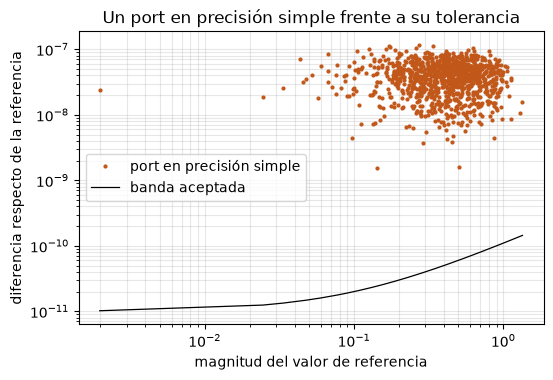

In [16]:
# the difference de los single-precision port against the magnitude de los reference, with the accepted band
magnitude = np.sort(size.ravel())
fig, ax = plt.subplots(figsize=(6.0, 3.8))
ax.loglog(size.ravel(), gap.ravel() + 1e-30, ".", color="#c2571a", markersize=4, label="port en precisión simple")
ax.loglog(magnitude, 1e-11 + 1e-10 * magnitude, "k-", linewidth=0.9, label="banda aceptada")
ax.set_xlabel("magnitud del valor de referencia")
ax.set_ylabel("diferencia respecto de la referencia")
ax.set_title("Un port en precisión simple frente a su tolerancia")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

La codificación del campo ocupa 49830 bytes y vuelve con una diferencia máxima de 0,0e+00, y el port que redondea sus fases de entrada a precisión simple difiere de la referencia en a lo más 1,2e-05 del valor en cualquier punto, de modo que un documento escrito con una tolerancia relativa de 1e-10 lo rechazaría, como mostrarían los puntos sobre la banda de la figura donde la crucen, mientras la tolerancia que lo acepta con un margen de diez es 1,2e-04. Esa es la decisión que el documento pide a su autor: escribe la tolerancia del port que quieres aceptar, y un port que no la cumple falla la prueba con el número que no alcanzó. La figura no dice si un port en precisión simple basta para la aplicación, solo si pasaría una referencia escrita en dobles; si una diferencia de este tamaño importa para los hologramas es una pregunta para los notebooks de los métodos, y la respuesta depende de cuántas iteraciones arrastren el error.

## Resultados

**Respuesta:** El motor TypeScript se mantiene dentro del de Python por una referencia guardada: 46 documentos con 119 casos con semilla, cada uno con un par de tolerancia que va de una relativa de 1e-14 a 1e-08, y un port se acepta cuando todo valor cumple la regla absoluta más relativa y todo flujo entero es idéntico. El motor de Python reproduce exactamente su propia referencia, 42 de 42 documentos regenerándose idénticos, y la regla es nítida: la fracción de valores aceptados cae de 1 a 0 en la tolerancia relativa del documento, y un port en precisión simple sería rechazado en los tres documentos probados. El documento de disponibilidad da a cada contrato un estado, con 7 de 11 disponibles y 2 parciales, y el contrato de la API responde un documento ausente con un cuerpo 503 que lleva el estado y la razón, en 6 de 8 rutas. Lo que el notebook no pudo hacer es correr el port de TypeScript contra la referencia, que es el trabajo de las pruebas del frontend.

## Resumen

- Un documento de referencia guarda entradas con semilla junto a las salidas del motor de Python y un par de tolerancia; un port se acepta cuando cada valor cumple la regla absoluta más relativa y cada flujo entero es idéntico.
- La referencia versionada se regenera exactamente desde el motor de Python, y la tolerancia es la resolución de la verificación: una diferencia bajo ella es invisible y sobre ella se rechaza todo valor.
- Un port en precisión simple fallaría las tolerancias de los documentos probados, por lo que el motor del navegador se queda en dobles.
- El documento de disponibilidad declara para cada contrato disponible, parcial, desactualizado, faltante, en entrenamiento o proveedor, con la razón y la lista de lo ausente, y el contrato de la API responde un documento ausente con un cuerpo 503 y nunca con uno vacío.
- Una referencia para una función propia necesita entradas con semilla, el codificador de la etapa y una tolerancia tomada de la mayor diferencia de un port real, un orden de magnitud sobre ella.

## Referencias

- Higham (2002). Accuracy and Stability of Numerical Algorithms, second edition. SIAM. https://doi.org/10.1137/1.9780898718027
- IEEE (2019). IEEE standard for floating-point arithmetic, IEEE Std 754-2019. https://doi.org/10.1109/IEEESTD.2019.8766229
- OpenAPI Initiative (2021). OpenAPI Specification, version 3.1.0. https://spec.openapis.org/oas/v3.1.0
- Goldberg (1991). What every computer scientist should know about floating-point arithmetic. ACM Computing Surveys 23, 5. https://doi.org/10.1145/103162.103163
- matplotlib 3.11.2, the plotting library of the notebooks. https://pypi.org/pypi/matplotlib/json